# Projet d'apprentissage pour l'image 
## Sujet: Transfert de couleur par transport optimal
_présenté par_ Eunice Sitti-Mawubejro

**Le transfer de couleur** est une méthode de traitement d'image dans laquelle on "transfert" les couleurs d'une image 1 dans une image 2 tout en gardant le contenu de l'image 2. 
Dans ce cas, l'image 1 (celle de laquelle on prend les couleurs) est appelée _Target image_ et l'image 2 (celle dans laquelle on tranfère les couleurs) est appelée _Input Image_ .

### Exemples de méthodes de transfert

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

In [2]:
#pip install opencv-python

In [3]:
import sys
#print(sys.path)
path = 'Images/'

In [4]:
# chargement des images 
imrgb1 = plt.imread(path+"parcfloral.png") #input image
imrgb2 = plt.imread(path+"parrot.png") #target image 
imrgb1=imrgb1[:,:,0:3]
imrgb2=imrgb2[:,:,0:3]

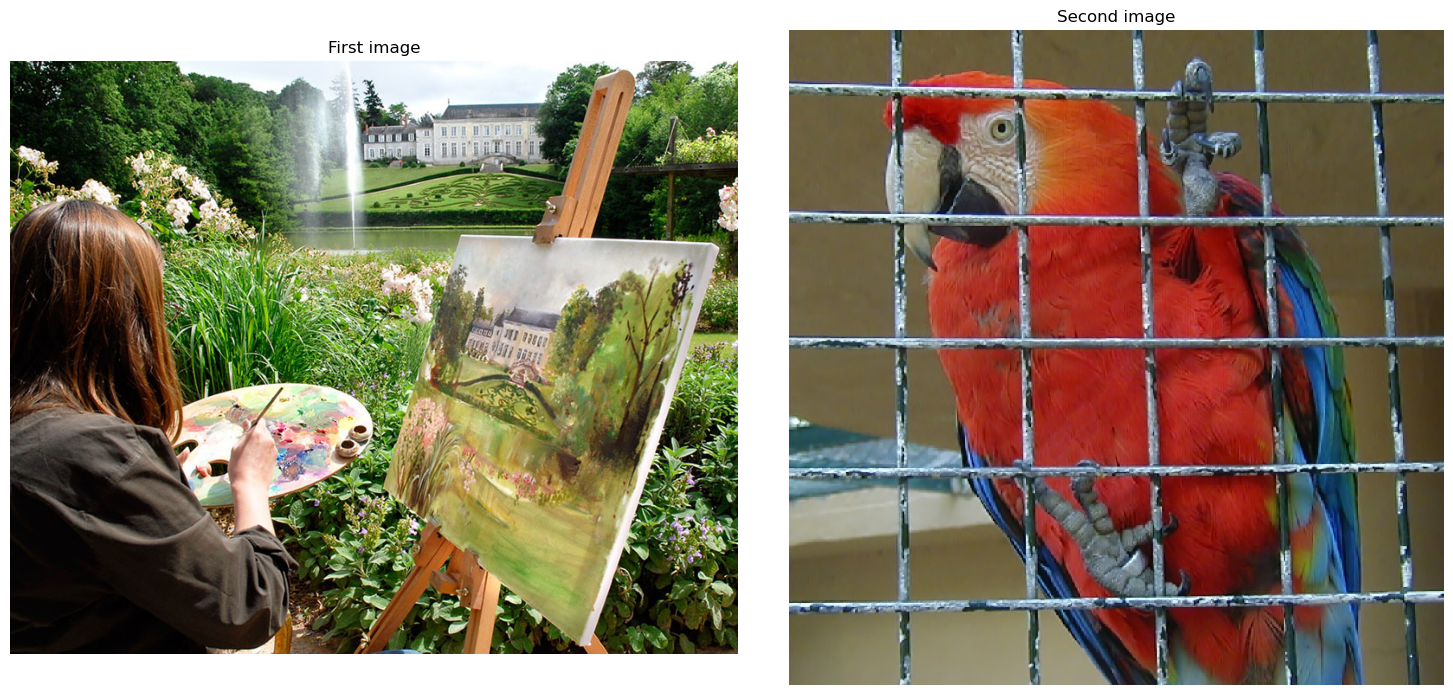

In [5]:
#affichage des image 
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 7))
axes[0].imshow(imrgb1)
axes[0].set_title('First image')
axes[0].axis('off')
axes[1].imshow(imrgb2)
axes[1].set_title('Second image')
axes[1].axis('off')
fig.tight_layout()
plt.show()

## Exemple 1: Transfert affine
L'idée ici est d'utiliser une transformation affine pour faire le transfert de couleur. Pour ce faire, la fonction affine-transfer applique une transformation linéaire à une image 1 pour qu'elle ai la même moyenne et ecart type que l'image 2.

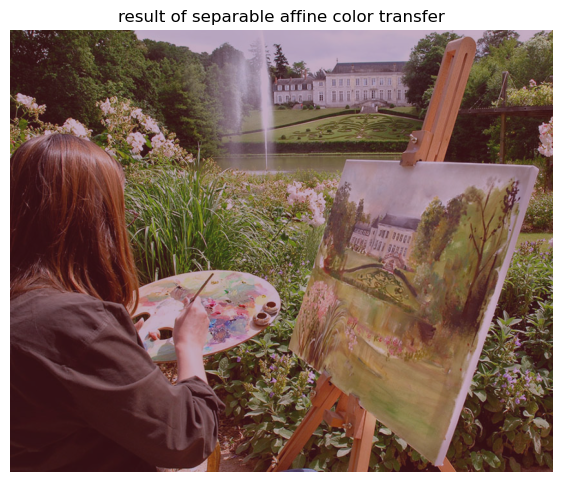

In [6]:
def affine_transfer(u,v):
    w = np.zeros(u.shape)
    for i in range(0,3):
        w[:,:,i] = (u[:,:,i] -np.mean(u[:,:,i]))/np.std(u[:,:,i])*np.std(v[:,:,i])+ np.mean(v[:,:,i])
    return w

# c'est une espèce de centrage et reduction
#ensuite on refait l'inverse avec le mean et le sd de l'autre image
w = affine_transfer(imrgb1,imrgb2)
w = (w>1)+(w<=1)*(w>0)*w  
#il faut que l'image soit entre [0,1]

#affichage
plt.figure(figsize=(7, 7))
plt.title('result of separable affine color transfer')
plt.axis('off')
plt.imshow(w)
plt.show()

In [ ]:
# visualisation des histogrammes


## Exemple 2 : Transfert par spécification de l'histogramme
L'idée ici est d'appliquer une spécification de l'histogramme à l'image u pour obtenir la distribution de couleur de l'image v.

In [7]:
# verification de la taille des images
[nrow1,ncol1,nch1]=imrgb1.shape
print(nrow1,ncol1,nch1)
[nrow2,ncol2,nch2]=imrgb2.shape
print(nrow2,ncol2,nch2)
#on voit que l'image l'image 1 est plus "grande" en taille que l'image 2.

685 841 3
495 495 3


In [8]:
# redimension de l'image 2
import cv2
imrgb2_resized = cv2.resize(imrgb2, (imrgb1.shape[1], imrgb1.shape[0]))

# verification de la taille des images
[nrow1,ncol1,nch1]=imrgb1.shape
print(nrow1,ncol1,nch1)
[nrow2,ncol2,nch2]=imrgb2.shape
print(nrow2,ncol2,nch2)
[nrow3,ncol3,nch3]=imrgb2_resized.shape
print(nrow3,ncol3,nch3)

# 
imrgb3 = imrgb2_resized.copy()

685 841 3
495 495 3
685 841 3


In [9]:
# specification 

def specification_transfer(u,v):
 [nrowu,ncolu,nchu]=u.shape
 uspecifv_rgb=np.zeros((nrowu,ncolu,3))

 for i in range(0,3):
    u = imrgb1[:,:,i]
    v = imrgb3[:,:,i]
    [nrowu,ncolu]=u.shape
    [nrowv,ncolv]=v.shape

    u_sort,index_u=np.sort(u,axis=None),np.argsort(u,axis=None)
    [v_sort,index_v]=np.sort(v,axis=None),np.argsort(v,axis=None)
    uspecifv= np.zeros(nrowu*ncolu)
    uspecifv[index_u] = v_sort
    uspecifv = uspecifv.reshape(nrowu,ncolu)
     
    uspecifv_rgb[:,:,i] =  uspecifv
 return uspecifv_rgb   


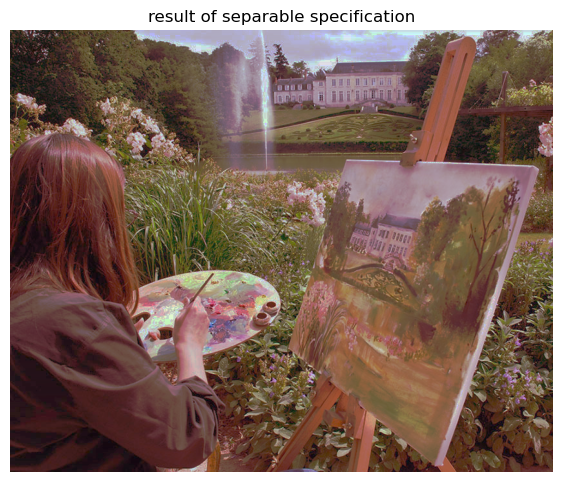

In [10]:
# affichage
w= specification_transfer(imrgb1,imrgb3)
plt.figure(figsize=(7, 7))
plt.title('result of separable specification')
plt.axis('off')
plt.imshow(w)
plt.show()


### Le transport optimal et le sliced transport
L'idée ici est d'utiliser le transport optimal pour "déformer" l'histogramme de l'input Image de manière plus efficace. Nous allons utiliser le "sliced transport".


## C'est quoi le tranport Optimal? et le sliced transport?
L'idée c'est que nous cherchons à déplacer une quantité d'objet donnée d'un endroit à un autre tout en minimisant le coût du transport.  

**Recap**: soit deux mesures de probabilités $\mu \in X$ $\nu \in Y$ et une fonction $c(\cdot,\cdot)$: $\begin{array}{ccccc}
c & : & X \times Y & \to &  \mathbb{R}_{+}
\end{array}$  
c est appelé coût.  
Un plan de transport optimal $T: X \to Y$ minimise: $\begin{equation}
\inf \left \{\int_X c(x,T(x)) d\mu(x) \mid T_*(\mu) = \nu \right \}
\end{equation}$ .  
Le coût du transfert optimal définie une distance entre des mesures.
On peut donc définir la $p^{ieme}$ distance de Wasserstrein, $W_p(\mu,\nu)$ par:
$\begin {equation}
W_p(\mu,\nu) := \left(\inf \left\{\int_X c(x,T(x)) d\mu(x) \mid T_*(\mu) = \nu \right \} \right)^{1/p}
\end {equation}$.  

__Analogie__ : pour se faire une idée, imaginez qu'on a une pile de sable qu'on veut mettre dans une chambre. $\mu$ est là où se trouve la pile de sable et $\nu$ est la chambre. Si on considère que le coût pour déplacer un grain de sable (ou un petit volume de sable) d'un lieu à un autre est proportionnelle à la distance euclidienne alors, le plan de transport optimal donne la manière la plus efficace pour déplacer toute la pile de sable dans la chambre( de $\mu$ vers$\nu$ ).  

Le lien avec le transfert de couleur est que les histogramme de couleur sont des mesures discretes de proba discrète. De ce fait un problème de transfert de couleur peut être interpréter comme un problème de transport optimal.

Il y'a plusieurs solution numérique à une problème de tranport optimal mais, ici, nous nous interesserons à la "sliced formulation".

La "sliced formulation", elle repose sur:  
. la projection des mesures $\mu$ et $\nu$ sur une droite (1D)
. ensuite, utilisation d'une permutation $\sigma$ pour "trier" les points projetés et on réassocie les points
. à la fin on fais le "chemin inverse" de la projection pour que les points de l'input image suivent la "voie" de celle de la target image

## Transport in 1D
Comme on veut "transporter" toute la distibution de couleur de l'image2  dans l'image1, on se propose "d'écrire" cette distribution comme un nuage de points en 3D: \begin{equation}
    X = \begin{pmatrix} X_1 \\ \vdots \\ X_n \end{pmatrix}, \quad Y = \begin{pmatrix} Y_1 \\ \vdots \\ Y_n \end{pmatrix},
\end{equation}

On cherche $\sigma$ qui minimise la quantité: \begin{equation}
    \sum_{i=1}^{n} \| X_i - Y_{\sigma(i)} \|_2^2.
\end{equation}  

**en 1D**: le $\sigma$ qui minimise la quantité est celle qui préserve l'ordre des points.

In [11]:
# Transport en dimension 1
#cette fonction prends points X et Y et donne la permutation $\sigma_X$ et $s\igma_Y$ 
def transport1D(X,Y):
    sx = np.argsort(X) #argsort retourne les indices des valeurs s'ils étaient ordonnés par ordre croissant
    sy = np.argsort(Y)
    return((sx,sy))

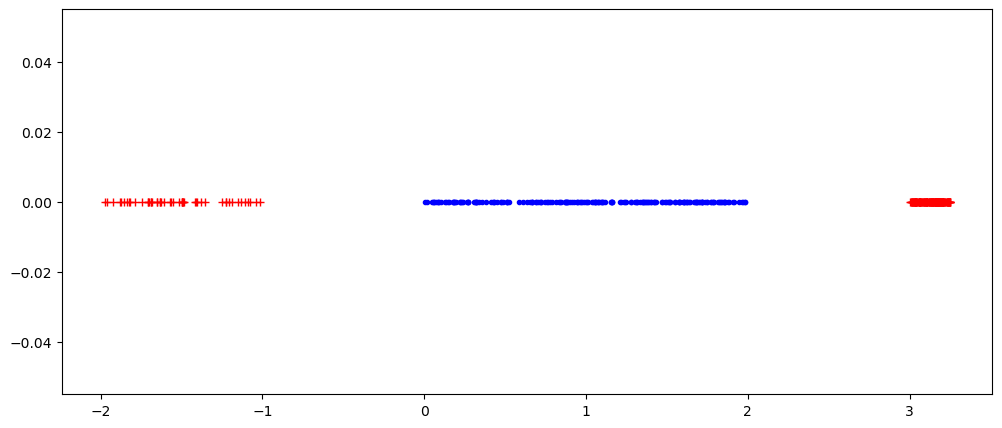

In [12]:
# visualisation des points qu'on a 
n = 200
X = 2 * np.random.rand(n)
Y = np.concatenate((
        np.random.rand(n//4)-2,
        .25*np.random.rand(3*n//4)+3))

plt.figure(figsize=(12, 5))
plt.plot(X,np.zeros(n),'.b')
plt.plot(Y,np.zeros(n),'+r')
plt.show()

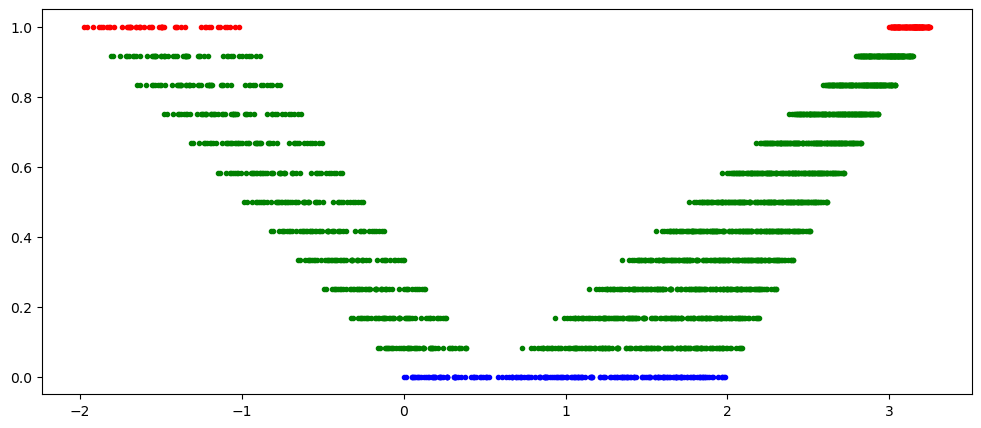

In [13]:
# visualisation de l'évolution de Z
sx, sy = transport1D(X,Y)
Z = np.zeros(n)
plt.figure(figsize=(12, 5))
plt.plot(X,np.zeros(n),'.b')
plt.plot(Y,np.ones(n),'.r')
n_steps = 12
for k in range(1,n_steps):
    Z[sx] = X[sx] + (k/n_steps) * (Y[sy]-X[sx])
    plt.plot(Z,(k/n_steps)*np.ones(n),'.g')
fig.tight_layout()
plt.show()

## Transport 3D
On veut toujours minimiser la même quantité mais pas que dans 1 dimension. Au lieu de faire un calcul, on écrit que la distance entre les points X et Y c'est la $\2^{ième}$ distance de Wasserstrein qui est définie par: \begin{equation}
    SW_2^2(X, Y) = \frac{1}{|S^2|} \int_{u \in S^2} \sum_{i=1}^{n} \left| \langle u, X_{\sigma_u^X(i)} \rangle - \langle u, Y_{\sigma_u^Y(i)} \rangle \right|^2 du,
\end{equation}


In [14]:
#cette fonction prend les nuages de points X, Y, le nombre d'itération N et e le pas pour le gradient
def transport3D(X,Y,N,e):
 Z= np.copy(X) #initialisation 
 u=np.random.randn(3,3)
 q=np.linalg.qr(u)[0] #pour obtenir une base ortho
 for j in range(N):
     
     for i in range(3):
         
         ui=q[:,i] #ieme vecteurs unité
    
    #les projections sur ui
         projx= np.dot(X,ui) #projection de X sur ui
         projy= np.dot(Y,ui) #projection de Y sur ui
         projz= np.dot(Z,ui) #projection de Z sur ui
    # les permutations sigma
         sx = np.argsort(projx) #pour avoir les indices comme dans transport1
         sy = np.argsort(projy) #pour avoir les indices comme dans transport1
         sz = np.argsort(projz) #pour avoir les indices comme dans transport1
    # z[sz]
         Z[sz] = Z[sz] + e*(projy[sy]-projz[sz])[:,np.newaxis]*ui #c'est dans le notebook et sans np.newaxis ça marche pas des max
 return Z,sz,sx

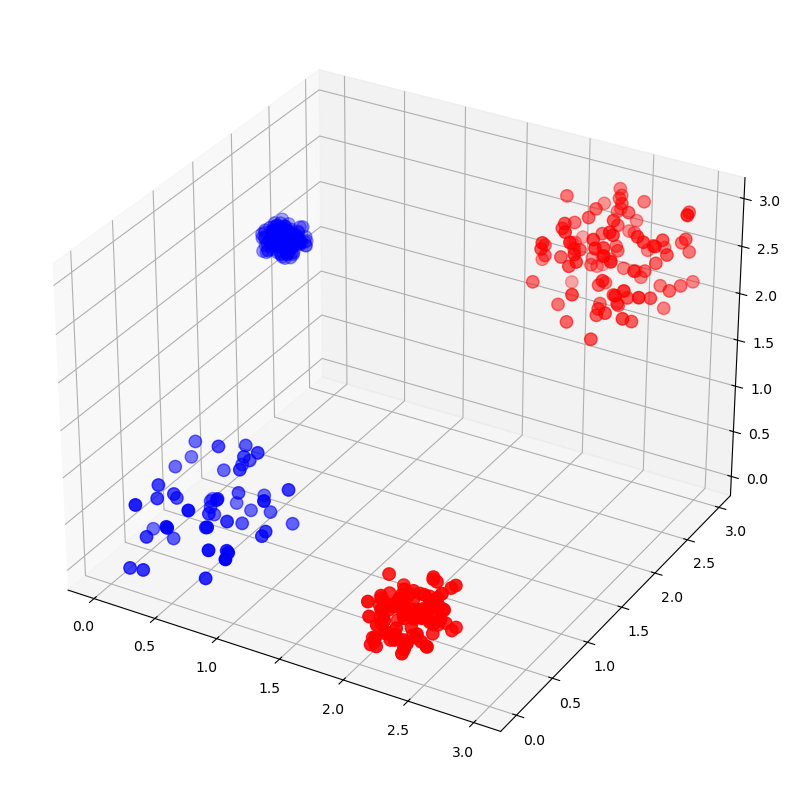

In [15]:
X = np.vstack((
        np.random.rand(50,3),
        .25 * np.random.rand(150,3) + np.array([[0,2,2]])
        ))
Y = np.vstack((
        np.random.rand(100,3) + np.array([[2,2,2]]),
        .5 * np.random.rand(100,3) + np.array([[2,0,0]])
        ))
fig = plt.figure(figsize=(10, 10))
axis = fig.add_subplot(1, 1, 1, projection="3d")
axis.scatter(X[:,0],X[:,1],X[:,2],c='blue',s=80)
axis.scatter(Y[:,0],Y[:,1],Y[:,2],c='red',s=80)
plt.show()

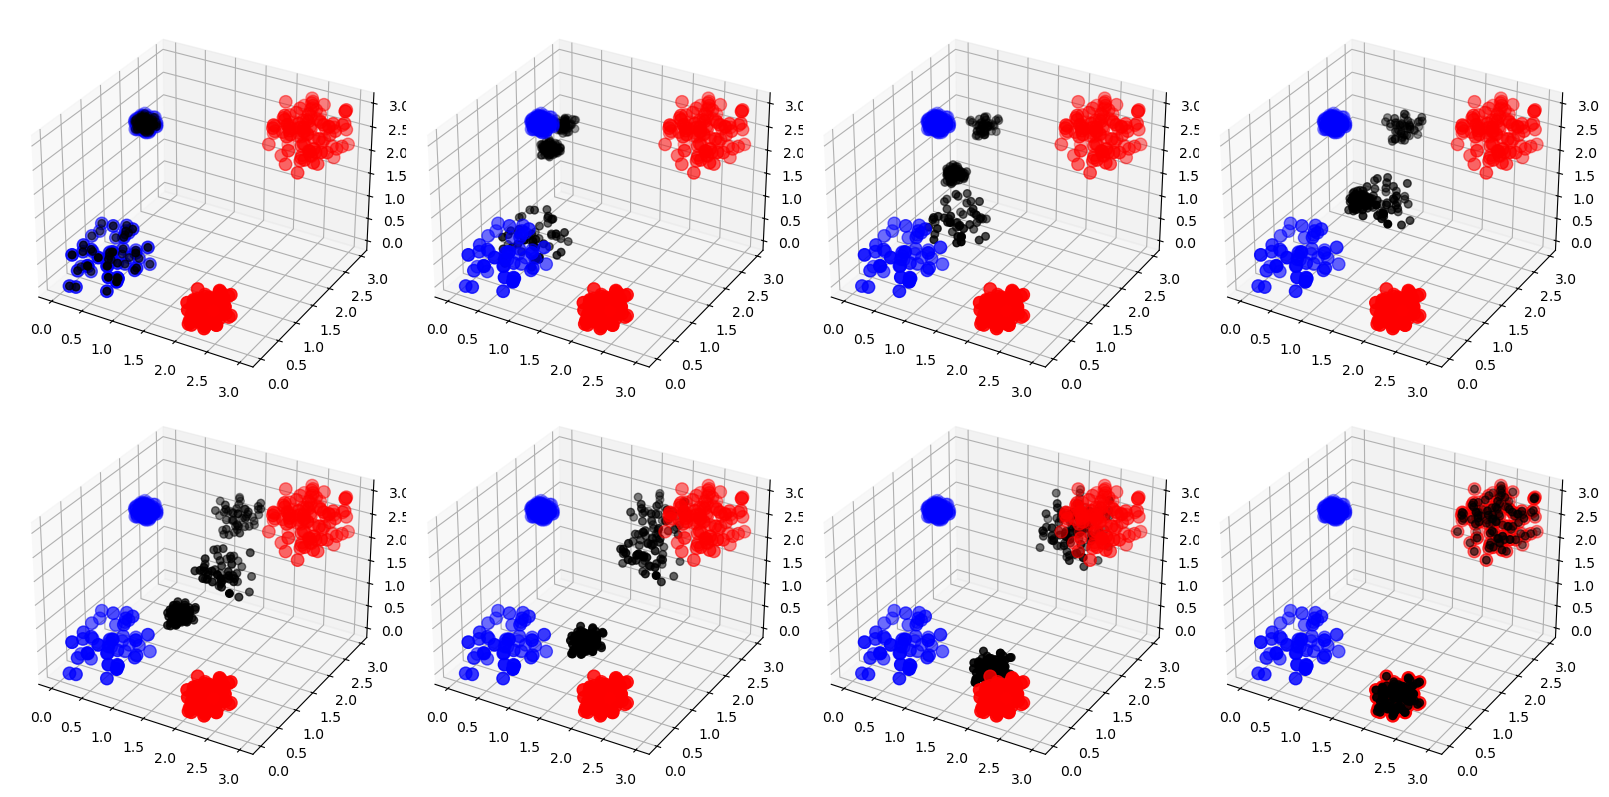

In [16]:
Z, sZ, sY = transport3D(X,Y,1000,0.1)

fig = plt.figure(figsize=(16, 8))
Z = np.zeros(X.shape)
k = 0
for i in range(4):
    for j in range(2):
        Z[sZ,:] = X[sZ,:] + (k/7) * (Y[sY,:]-X[sZ,:])
        ax = fig.add_subplot(2, 4, k+1, projection="3d")
        ax.scatter(X[:,0],X[:,1],X[:,2],c='blue',s=80)
        ax.scatter(Y[:,0],Y[:,1],Y[:,2],c='red',s=80)
        ax.scatter(Z[:,0],Z[:,1],Z[:,2],c='black',s=30)
        k += 1
fig.tight_layout()
plt.show()

## Application au transfert de couleur

In [17]:
#ici c'est pour avoir un nuage de points un peu moins nombreux qu'en totale résolution pour que la travail se fasse vite
# choose s=10 or larger in your session!!!
u = imrgb1
v = imrgb3
s = 1
                          
if s==1:
    usubsample = u
    vsubsample = v
else:
    usubsample = u[1::s,1::s,0:3]
    vsubsample = v[1::s,1::s,0:3]

X = usubsample.reshape((usubsample.shape[0]*usubsample.shape[1],3))
Y = vsubsample.reshape((vsubsample.shape[0]*vsubsample.shape[1],3))

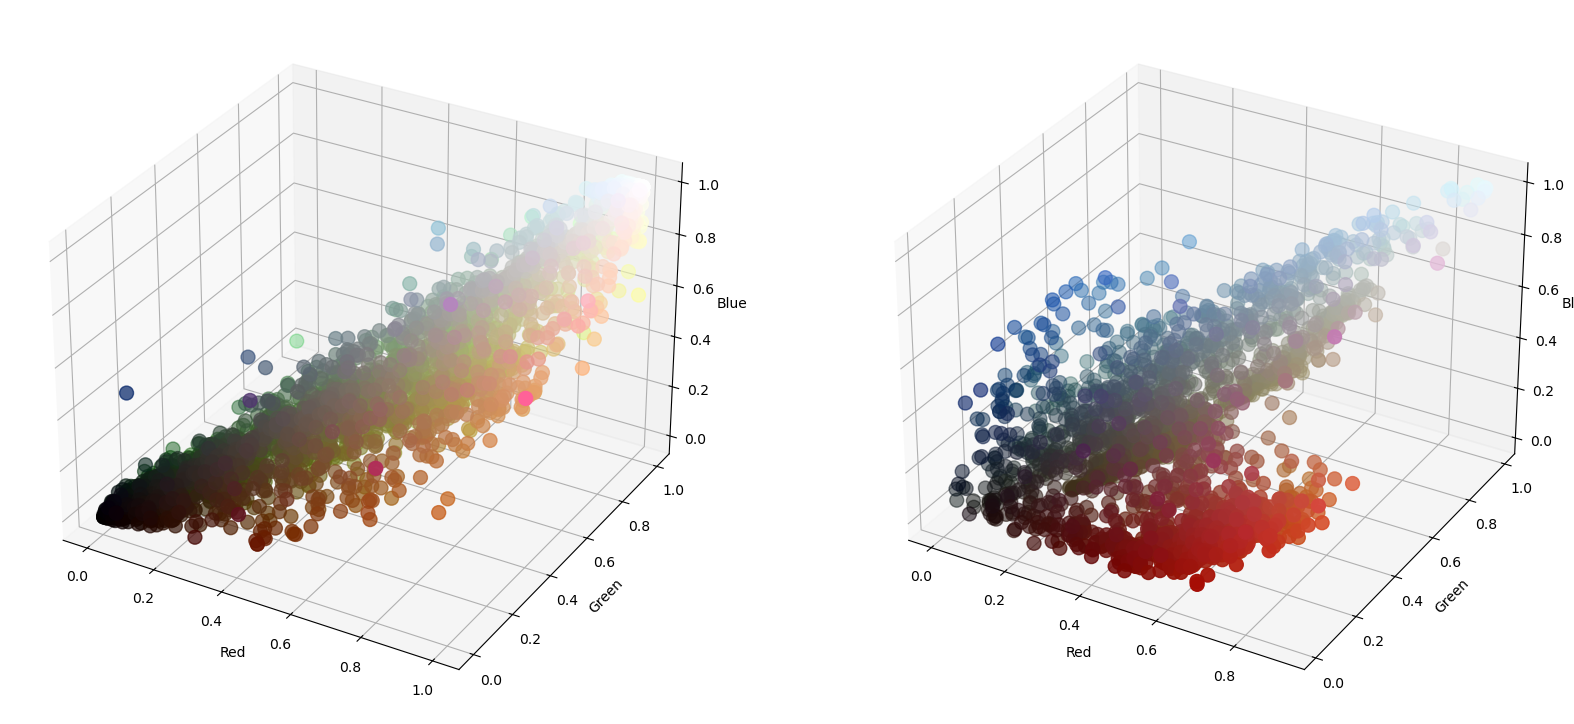

In [18]:
#ce à quoi ressemble le nuage de points
nb = 3000
r = np.random.RandomState(42)
idX = r.randint(X.shape[0], size=(nb,))
idY = r.randint(Y.shape[0], size=(nb,))
Xs = X[idX, :]
Ys = Y[idY, :]

fig = plt.figure(2, figsize=(20, 10))
axis = fig.add_subplot(1, 2, 1, projection="3d")
axis.scatter(Xs[:, 0], Xs[:,1],Xs[:, 2], c=Xs,s=100)
axis.set_xlabel("Red"), axis.set_ylabel("Green"), axis.set_zlabel("Blue")
axis = fig.add_subplot(1, 2, 2, projection="3d")
axis.scatter(Ys[:, 0], Ys[:,1],Ys[:, 2], c=Ys,s=100)
axis.set_xlabel("Red"), axis.set_ylabel("Green"), axis.set_zlabel("Blue")
plt.show()

In [19]:
X_new, order_X_new, s_Y= transport3D(X,Y,1000,0.2)
wsliced = X_new.reshape(usubsample.shape[0],usubsample.shape[1],3)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0747611..1.0141098].


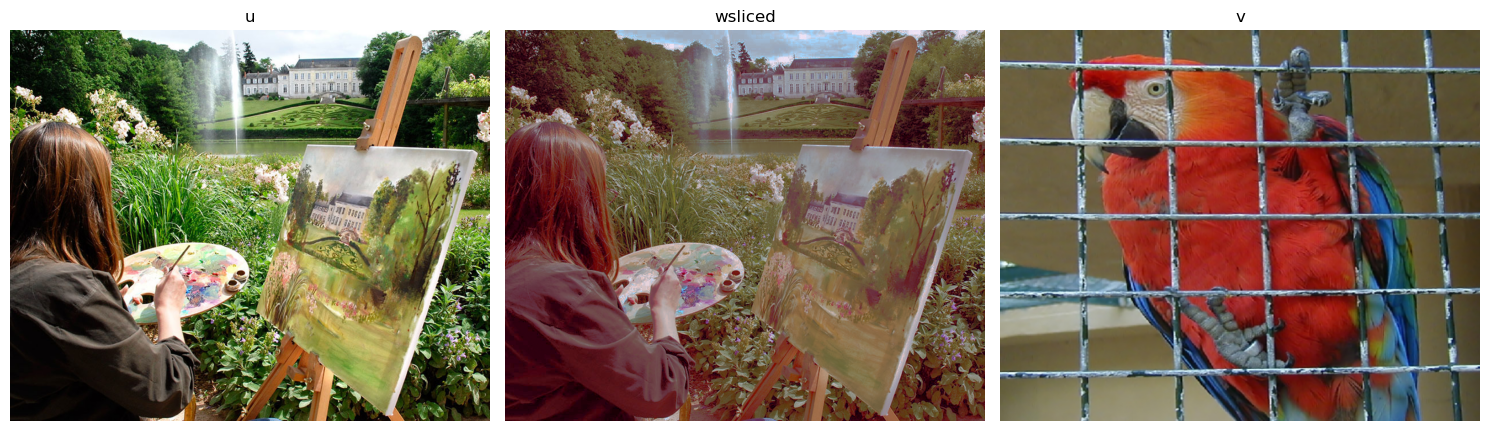

In [20]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 7))
axes[0].imshow(usubsample)
axes[0].set_title('u')
axes[0].axis('off')
axes[1].imshow(wsliced)
axes[1].set_title('wsliced')
axes[1].axis('off')
axes[2].imshow(vsubsample)
axes[2].set_title('v')
axes[2].axis('off')
fig.tight_layout()
plt.show()

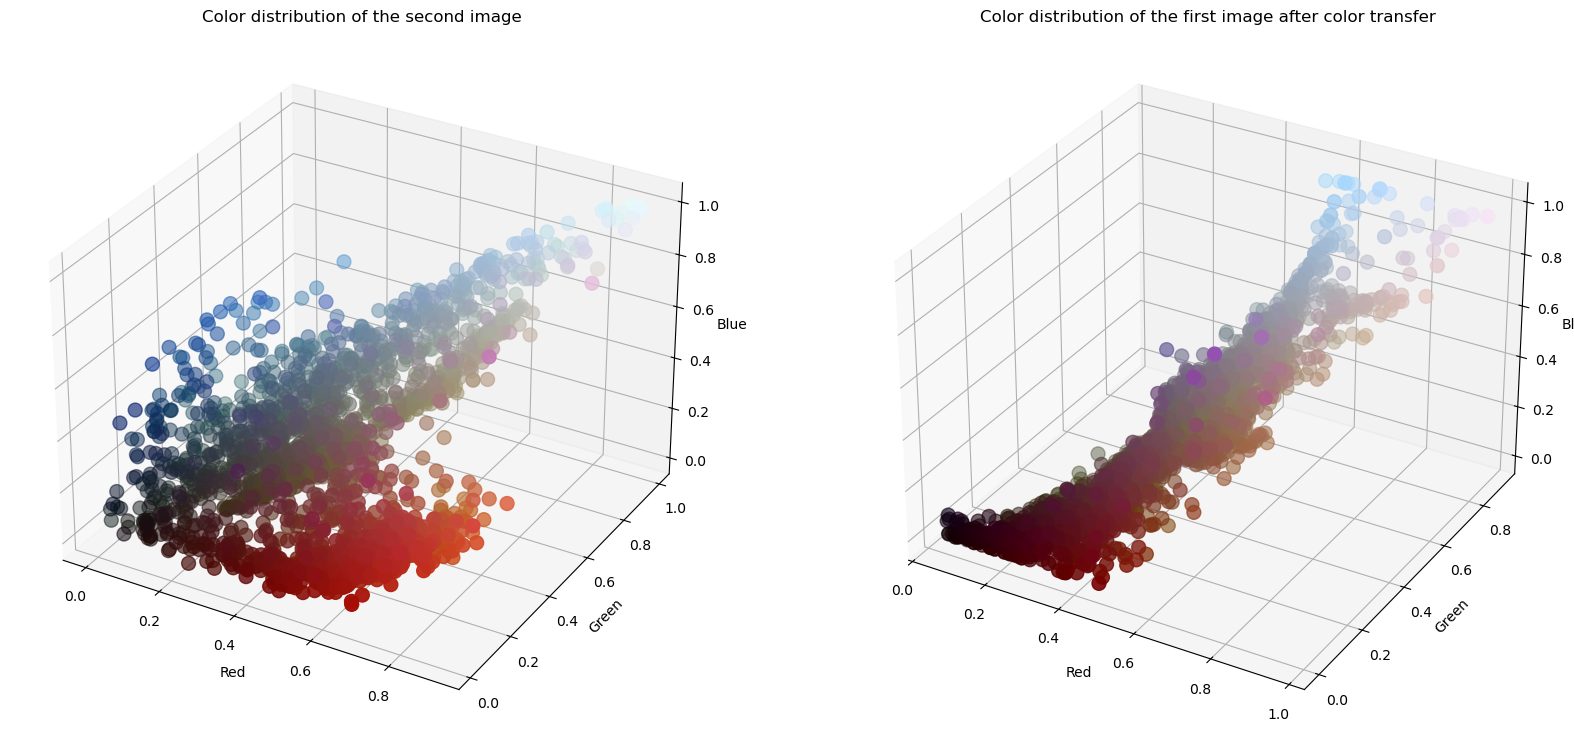

In [21]:
idZ = r.randint(X_new.shape[0], size=(nb,))
Zs = X_new[idZ, :]
Zs = (Zs>1)+(Zs<1)*(Zs>0)*Zs           # to ensure that colors are in [0,1]^3

fig = plt.figure(2, figsize=(20, 10))
axis = fig.add_subplot(1, 2, 1, projection="3d")
axis.scatter(Ys[:, 0], Ys[:,1],Ys[:, 2], c=Ys,s=100)
axis.set_xlabel("Red")
axis.set_ylabel("Green")
axis.set_zlabel("Blue")
axis.set_title('Color distribution of the second image')
axis = fig.add_subplot(1, 2, 2, projection="3d")
axis.scatter(Zs[:, 0], Zs[:,1],Zs[:, 2], c=Zs,s=100)
axis.set_xlabel("Red")
axis.set_ylabel("Green")
axis.set_zlabel("Blue")
axis.set_title('Color distribution of the first image after color transfer')
plt.show()

Ici, il s'agit de filter et ou lisser un peu l'mage obtenu pour que les couleurs passent bien

In [22]:
usubsample = imrgb1

usubsample_resized = cv2.resize(usubsample, (wsliced.shape[1], wsliced.shape[0]))
wsliced = wsliced[:,:,0:3]


In [23]:
def average_filter(u,r):
    # uniform filter with a square (2*r+1)x(2*r+1) window
    # u is a 2d image
    # r is the radius for the filter

    (nrow, ncol) = u.shape
    big_uint = np.zeros((nrow+2*r+1,ncol+2*r+1))
    big_uint[r+1:nrow+r+1,r+1:ncol+r+1] = u
    big_uint = np.cumsum(np.cumsum(big_uint,0),1)  # integral image

    out = big_uint[2*r+1:nrow+2*r+1,2*r+1:ncol+2*r+1] + big_uint[0:nrow,0:ncol] - big_uint[0:nrow,2*r+1:ncol+2*r+1] - big_uint[2*r+1:nrow+2*r+1,0:ncol]
    out = out/(2*r+1)**2

    return out

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0747611..1.0141098].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2156032..1.1946257].


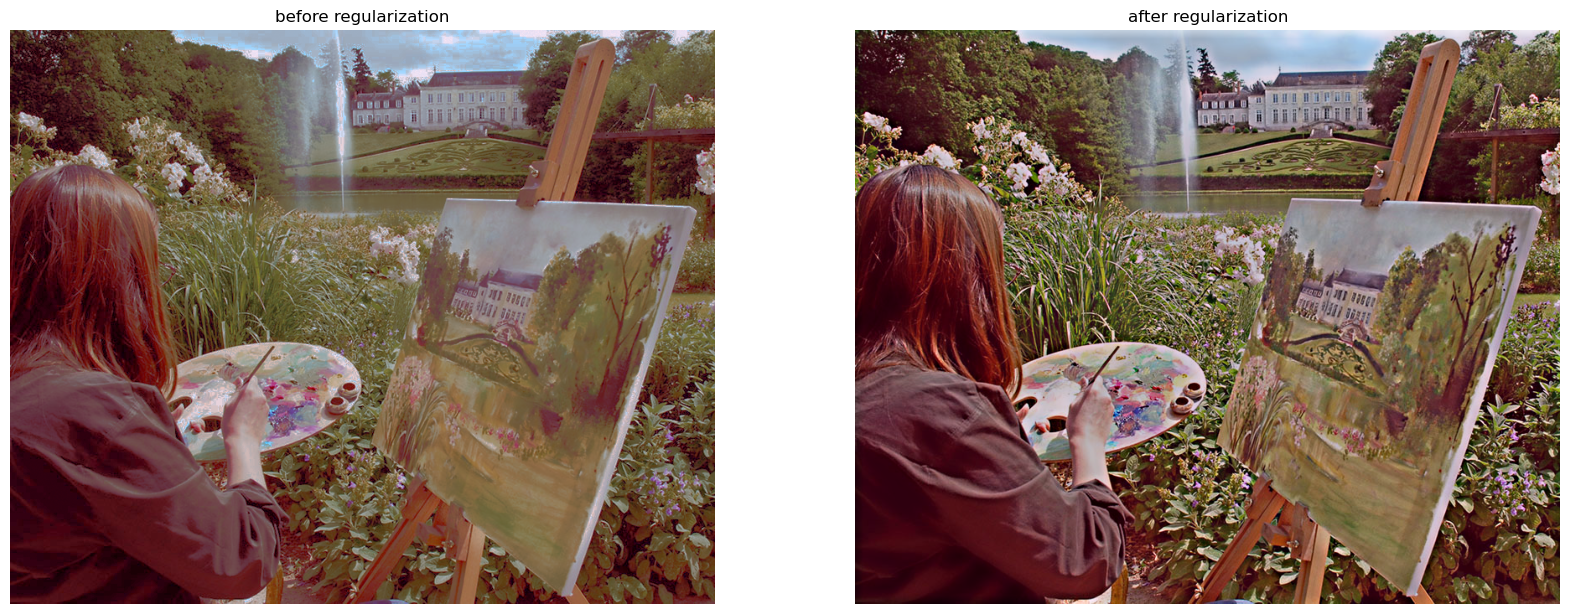

In [24]:
diff = wsliced - usubsample
out = np.zeros_like(usubsample)
r=10
for i in range(3):
    out[:,:,i] = average_filter(diff[:,:,i], r)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))
axes[0].imshow(wsliced)
axes[0].set_title('before regularization')
axes[0].axis('off')
axes[1].set_title('after regularization')
axes[1].axis('off')
axes[1].imshow(usubsample+out)
plt.show()